# Random Forest Regression: Next-Game Points Prediction

This notebook trains a Random Forest model to predict how many points a player scores in a game, using only information available **before** tip-off. It uses the same dataset, features, train/test split and metrics as `linear_regression.ipynb` and the baselines in `ml/EDA/prediction_baseline.ipynb`, so all of them can be compared directly.

**Target definition:** every feature in a row is built from the player's *earlier* games (`shift(1)`), so predicting that row's `points` is a next-game prediction. A game's own stats never feed its features.

**Why a Random Forest:** Linear Regression can only learn a weighted sum of the features. A Random Forest averages many decision trees, so it can pick up non-linear effects and interactions, for example recent minutes mattering more for some scoring levels than others.

**About the split:** train is the 2024-25 season for all 84 players. Test is the 2025-26 season, which in this dataset has only **one player (Stephen Curry)**. The time-series cross-validation on train, which covers all 84 players, is used for tuning and is the better guide to general accuracy.

## Config

- `POINTS_DATA_PATH` (environment variable): set it to use a different feature CSV. If it is not set, the notebook uses `data/sample/player_game_stats_sample_features.csv`.
- `BASE_FEATURES` / `CONTEXT_FEATURES`: the same five pre-game features the Linear Regression uses.
- `PARAM_GRID`: the hyperparameters tried during tuning. Each combination is scored with time-series cross-validation on train only.
- `SAVE_MODEL`: off by default so running the notebook does not create files.

In [14]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Make the repo root importable so the shared feature code can be used here.
REPO_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents) if (root / 'data' / 'processing' / 'points_features.py').exists()),
    None,
)
assert REPO_ROOT is not None, 'Could not find the repo root (data/processing/points_features.py)'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.processing.modeling_features import add_modeling_context
from data.processing.points_features import FEATURE_COLS, time_split

# Dataset: override with the POINTS_DATA_PATH environment variable.
DATA_RELATIVE_PATH = Path('data') / 'sample' / 'player_game_stats_sample_features.csv'
DATA_PATH = Path(os.environ.get('POINTS_DATA_PATH', REPO_ROOT / DATA_RELATIVE_PATH))
assert DATA_PATH.exists(), f'Could not find {DATA_PATH}; run ml/EDA/feature_engineering.ipynb first'

BASELINE_METRICS_PATH = REPO_ROOT / 'ml' / 'EDA' / 'baseline_metrics.csv'

TARGET = 'points'
BASE_FEATURES = list(FEATURE_COLS)
CONTEXT_FEATURES = ['is_home', 'recent_minutes_avg']
FEATURES = BASE_FEATURES + CONTEXT_FEATURES

TRAIN_FRACTION = 0.8  # only used if the CSV has no split column
CV_SPLITS = 5
RANDOM_STATE = 42

N_ESTIMATORS = 300
PARAM_GRID = {
    'max_depth': [None, 6, 10],
    'min_samples_leaf': [1, 10, 30],
    'max_features': [1.0, 'sqrt'],
}

SAVE_MODEL = True
ARTIFACT_DIR = REPO_ROOT / 'ml' / 'models' / 'artifacts'

print(DATA_PATH)
print('Features:', FEATURES)

/Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/data/sample/player_game_stats_sample_features.csv
Features: ['pts_season_avg', 'pts_last5_avg', 'pts_last10_avg', 'is_home', 'recent_minutes_avg']


## Load and validate the dataset

`game_id` is read as a string to keep its leading zeros. If a CSV without a `split` column is used, the same chronological 80/20 split from `time_split` is applied here.

In [2]:
features = pd.read_csv(DATA_PATH, dtype={'game_id': str}, parse_dates=['game_date'])

required = {'player_id', 'game_date', 'matchup', 'minutes', TARGET, *BASE_FEATURES}
missing = required - set(features.columns)
assert not missing, f'Missing columns: {missing}'

if 'split' not in features.columns:
    features = time_split(features, train_fraction=TRAIN_FRACTION)
    print(f'No split column found; applied a {TRAIN_FRACTION:.0%} chronological split')

assert set(features['split']) <= {'train', 'test'}
assert features.loc[features['split'] == 'train', 'game_date'].max() < features.loc[features['split'] == 'test', 'game_date'].min()

print(features.shape)
features.groupby('split').agg(
    rows=('game_date', 'size'),
    players=('player_id', 'nunique'),
    first_game=('game_date', 'min'),
    last_game=('game_date', 'max'),
)

(5047, 35)


,rows,players,first_game,last_game
split,,,,
test,42,1,2025-10-23,2026-04-12
train,5005,84,2024-10-22,2025-10-21


## Pre-game context features

`is_home` and `recent_minutes_avg` are already in the dataset. `add_modeling_context` only runs if they are missing. `is_home` is stored as True/False, so it is converted to 0/1.

In [3]:
if not set(CONTEXT_FEATURES) <= set(features.columns):
    features = add_modeling_context(features)
    print('Added context features with add_modeling_context')

features['is_home'] = features['is_home'].astype(int)

## Build the training and test sets

Rows with no points history (each player's first game) are dropped, so the model is scored on exactly the same games as the baselines and the Linear Regression.

In [4]:
model_rows = features.dropna(subset=BASE_FEATURES).sort_values(['game_date', 'player_id']).reset_index(drop=True)

dropped = features['split'].value_counts().sub(model_rows['split'].value_counts(), fill_value=0).astype(int)
print('Rows dropped per split:')
print(dropped.to_string())

train = model_rows[model_rows['split'] == 'train']
test = model_rows[model_rows['split'] == 'test']

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f'\ntrain: {len(train)} rows, {train["player_id"].nunique()} players | '
      f'test: {len(test)} rows, {test["player_id"].nunique()} players')

Rows dropped per split:
split
train    85
test      0

train: 4920 rows, 84 players | test: 42 rows, 1 players


## Models and evaluation helpers

- **Random Forest**: a median imputer, then `RandomForestRegressor`. Trees split on thresholds, so the features do not need scaling.
- **Linear Regression**: the same pipeline as `linear_regression.ipynb`. It is refit here so both models are scored on identical folds.

`cv_folds` builds the time-series folds from unique game dates. Each fold trains on earlier dates and validates on the dates right after them, so no fold trains on the future, and every game day stays in a single fold.

In [5]:
def make_rf(**params):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('model', RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1, **params)),
    ])


def make_lr():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LinearRegression()),
    ])


def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }


def cv_folds(frame, n_splits):
    dates = np.sort(frame['game_date'].unique())
    splitter = TimeSeriesSplit(n_splits=min(n_splits, len(dates) - 1))
    return [(frame['game_date'].isin(dates[fit_idx]), frame['game_date'].isin(dates[val_idx]))
            for fit_idx, val_idx in splitter.split(dates)]


def cross_validate(make_model):
    """Score a model on FOLDS; returns per-fold metrics and out-of-fold predictions."""
    fold_rows, oof_parts = [], []
    for fold, (fit_mask, val_mask) in enumerate(FOLDS, start=1):
        fold_model = make_model().fit(X_train[fit_mask], y_train[fit_mask])
        val_pred = fold_model.predict(X_train[val_mask])
        fold_rows.append({'fold': fold, 'n_fit': int(fit_mask.sum()), 'n_val': int(val_mask.sum()),
                          **evaluate(y_train[val_mask], val_pred)})
        oof_parts.append(train.loc[val_mask, ['player_id', 'player_name', 'game_date', TARGET]]
                         .assign(predicted=val_pred, fold=fold))
    return pd.DataFrame(fold_rows), pd.concat(oof_parts)


FOLDS = cv_folds(train, CV_SPLITS)
assert len(FOLDS) >= 2, 'Not enough training dates for cross-validation'
print(f'{len(FOLDS)} time-series folds')

5 time-series folds


## Hyperparameter tuning (train only)

Each combination in `PARAM_GRID` is scored by its mean MAE over the time-series folds. The test set is not used here.

- `max_depth`: how deep each tree can grow. Shallower trees are simpler.
- `min_samples_leaf`: the minimum number of games in each leaf. Larger values smooth the predictions and reduce overfitting.
- `max_features`: how many features each split can consider. `'sqrt'` makes the trees more different from each other.

In [6]:
grid = list(ParameterGrid(PARAM_GRID))
tuning_rows = []
for i, params in enumerate(grid):
    fold_metrics, _ = cross_validate(lambda: make_rf(**params))
    tuning_rows.append({'candidate': i, **{k: str(v) for k, v in params.items()},
                        'MAE_mean': fold_metrics['MAE'].mean(), 'MAE_std': fold_metrics['MAE'].std(),
                        'RMSE_mean': fold_metrics['RMSE'].mean(), 'R2_mean': fold_metrics['R2'].mean()})

tuning = pd.DataFrame(tuning_rows).sort_values('MAE_mean').reset_index(drop=True).round(3)
best_params = grid[tuning.loc[0, 'candidate']]
print(f'Best parameters: {best_params} (CV MAE {tuning.loc[0, "MAE_mean"]:.3f})')
tuning.drop(columns='candidate')

Best parameters: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 30} (CV MAE 5.368)


,max_depth,max_features,min_samples_leaf,MAE_mean,MAE_std,RMSE_mean,R2_mean
0,6,sqrt,30,5.368,0.079,6.891,0.564
1,None,sqrt,30,5.370,0.077,6.893,0.564
2,10,sqrt,30,5.371,0.077,6.893,0.564
3,6,sqrt,10,5.402,0.087,6.923,0.560
4,6,1.0,30,5.410,0.082,6.940,0.558
5,10,1.0,30,5.416,0.080,6.944,0.557
6,None,1.0,30,5.416,0.080,6.945,0.557
7,6,sqrt,1,5.423,0.090,6.941,0.558
8,10,sqrt,10,5.425,0.072,6.951,0.557
9,None,sqrt,10,5.427,0.072,6.956,0.556


## Cross-validation comparison

All three models are scored on the same folds. This is the main multi-player comparison, because the test set has only one player. The tuned forest was chosen with these same folds, so its score is slightly optimistic.

In [7]:
candidates = {
    'Random Forest (tuned)': lambda: make_rf(**best_params),
    'Random Forest (default)': make_rf,
    'Linear Regression': make_lr,
}

cv_summary_rows, oof_by_model = [], {}
for name, make_model in candidates.items():
    fold_metrics, oof_by_model[name] = cross_validate(make_model)
    cv_summary_rows.append({'model': name,
                            'MAE': f"{fold_metrics['MAE'].mean():.3f} ± {fold_metrics['MAE'].std():.3f}",
                            'RMSE': round(fold_metrics['RMSE'].mean(), 3),
                            'R2': round(fold_metrics['R2'].mean(), 3)})

cv_summary = pd.DataFrame(cv_summary_rows)
cv_summary

,model,MAE,RMSE,R2
0,Random Forest (tuned),5.368 ± 0.079,6.891,0.564
1,Random Forest (default),5.709 ± 0.074,7.266,0.516
2,Linear Regression,5.380 ± 0.074,6.895,0.564


## Fit on the full training set and evaluate

The tuned forest and the Linear Regression are fit on all training rows. The **test** rows give the headline numbers. Train numbers are shown so overfitting is visible.

In [8]:
rf_pipeline = make_rf(**best_params).fit(X_train, y_train)
lr_pipeline = make_lr().fit(X_train, y_train)

rf_test_pred = rf_pipeline.predict(X_test)
lr_test_pred = lr_pipeline.predict(X_test)

model_results = pd.DataFrame([
    {'model': 'Random Forest', 'split': 'train', 'n': len(train), **evaluate(y_train, rf_pipeline.predict(X_train))},
    {'model': 'Random Forest', 'split': 'test', 'n': len(test), **evaluate(y_test, rf_test_pred)},
    {'model': 'Linear Regression', 'split': 'train', 'n': len(train), **evaluate(y_train, lr_pipeline.predict(X_train))},
    {'model': 'Linear Regression', 'split': 'test', 'n': len(test), **evaluate(y_test, lr_test_pred)},
]).round(3)
model_results

,model,split,n,MAE,RMSE,R2
0,Random Forest,train,4920,5.217,6.743,0.590
1,Random Forest,test,42,8.114,10.569,-0.052
2,Linear Regression,train,4920,5.382,6.950,0.565
3,Linear Regression,test,42,8.123,10.640,-0.066


## Compare with the baselines

The baseline metrics come from `ml/EDA/prediction_baseline.ipynb`. They only compare fairly when they were computed on the same dataset, so a warning is printed if the row counts differ.

In [9]:
MODEL_NAMES = ['Random Forest', 'Linear Regression']

if BASELINE_METRICS_PATH.exists():
    baselines = pd.read_csv(BASELINE_METRICS_PATH).rename(columns={'baseline': 'model'})
    comparison = pd.concat([baselines, model_results], ignore_index=True)

    if comparison.groupby('split')['n'].nunique().max() > 1:
        print('WARNING: baseline and model row counts differ; re-run prediction_baseline.ipynb on this dataset.')

    test_comparison = comparison[comparison['split'] == 'test'].sort_values('MAE').reset_index(drop=True)
    best_baseline = test_comparison[~test_comparison['model'].isin(MODEL_NAMES)].iloc[0]
    rf_mae = model_results.query("model == 'Random Forest' and split == 'test'")['MAE'].iloc[0]
    verdict = 'beats' if rf_mae < best_baseline['MAE'] else 'does not beat'
    print(f"Random Forest test MAE {rf_mae:.3f} {verdict} the best baseline "
          f"({best_baseline['model']}, MAE {best_baseline['MAE']:.3f})")
    display(test_comparison)
else:
    comparison = model_results
    print(f'No baseline metrics at {BASELINE_METRICS_PATH}; run prediction_baseline.ipynb to compare.')

Random Forest test MAE 8.114 beats the best baseline (Last 10 avg, MAE 8.179)


,model,split,n,MAE,RMSE,R2
0,Random Forest,test,42,8.114,10.569,-0.052
1,Linear Regression,test,42,8.123,10.640,-0.066
2,Last 10 avg,test,42,8.179,10.471,-0.033
3,Season avg,test,42,8.348,10.925,-0.124
4,Last 5 avg,test,42,8.600,11.273,-0.197


## Feature importance

- **Impurity importance** comes from the fitted forest: how much each feature reduces error across all the splits that use it. It is cheap to compute, but it can favor continuous features.
- **Permutation importance** is how much the MAE gets worse, in points, when one feature's values are shuffled. It is measured on the last cross-validation fold, with the model fit only on earlier dates, so it covers many players rather than the single test player.

The three points averages are strongly correlated with each other, so they share credit. Shuffling one of them hurts less than its real contribution, because the others still carry the same information.

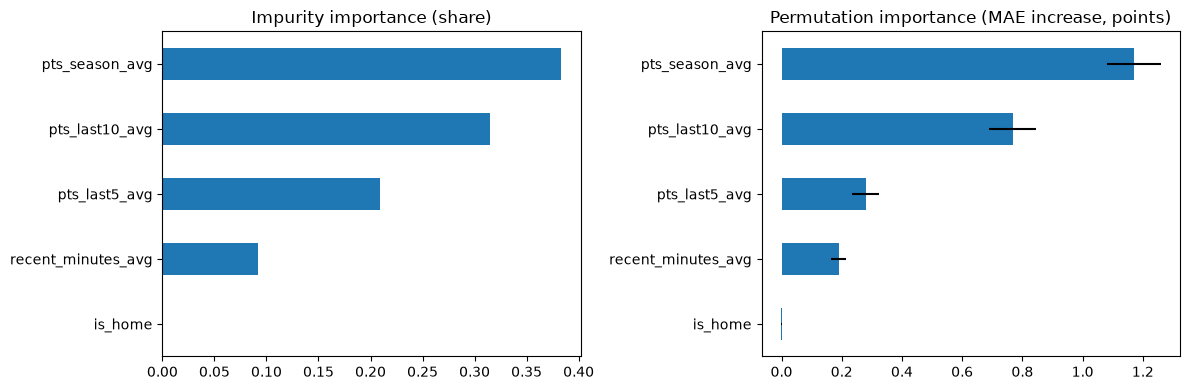

,impurity,permutation_MAE_increase
pts_season_avg,0.383,1.171
pts_last10_avg,0.315,0.768
pts_last5_avg,0.209,0.279
recent_minutes_avg,0.092,0.190
is_home,0.001,-0.001


In [10]:
impurity = pd.Series(rf_pipeline.named_steps['model'].feature_importances_, index=FEATURES)

fit_mask, val_mask = FOLDS[-1]
perm_model = make_rf(**best_params).fit(X_train[fit_mask], y_train[fit_mask])
perm = permutation_importance(perm_model, X_train[val_mask], y_train[val_mask],
                              scoring='neg_mean_absolute_error', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
permutation = pd.Series(perm.importances_mean, index=FEATURES)

importance = (pd.DataFrame({'impurity': impurity, 'permutation_MAE_increase': permutation})
              .sort_values('permutation_MAE_increase', ascending=False).round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
importance['impurity'].sort_values().plot.barh(ax=ax1, title='Impurity importance (share)')
importance['permutation_MAE_increase'].sort_values().plot.barh(
    ax=ax2, xerr=pd.Series(perm.importances_std, index=FEATURES), title='Permutation importance (MAE increase, points)')
plt.tight_layout()
plt.show()

importance

## Predicted vs. actual (test)

Points on the dashed line are perfect predictions. The middle plot shows whether the errors drift over time. The right plot compares the forest's predictions with the Linear Regression's on the same games: points near the line mean the two models mostly agree.

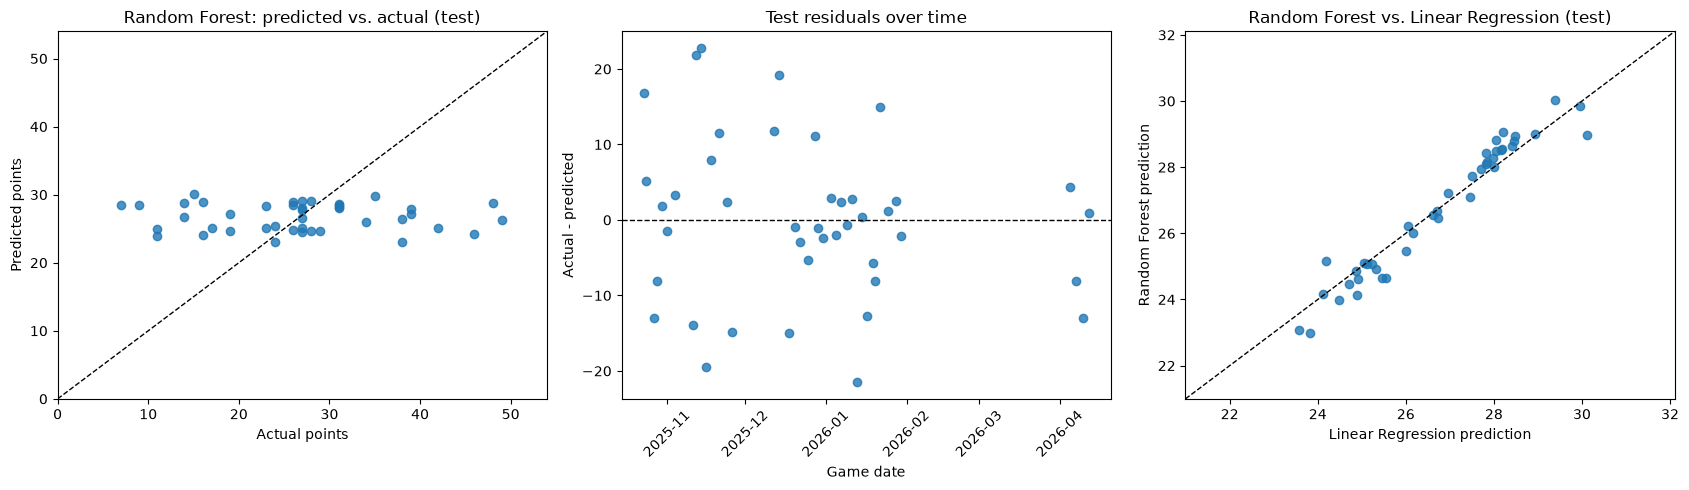

In [11]:
results = test[['player_id', 'player_name', 'game_date', TARGET]].assign(predicted=rf_test_pred)
results['residual'] = results[TARGET] - results['predicted']

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))

lims = [0, max(results[TARGET].max(), results['predicted'].max()) + 5]
ax1.scatter(results[TARGET], results['predicted'], alpha=0.8)
ax1.plot(lims, lims, 'k--', linewidth=1)
ax1.set(xlim=lims, ylim=lims, xlabel='Actual points', ylabel='Predicted points',
        title='Random Forest: predicted vs. actual (test)')

ax2.scatter(results['game_date'], results['residual'], alpha=0.8)
ax2.axhline(0, color='k', linestyle='--', linewidth=1)
ax2.set(xlabel='Game date', ylabel='Actual - predicted', title='Test residuals over time')
ax2.tick_params(axis='x', rotation=45)

pred_lims = [min(rf_test_pred.min(), lr_test_pred.min()) - 2, max(rf_test_pred.max(), lr_test_pred.max()) + 2]
ax3.scatter(lr_test_pred, rf_test_pred, alpha=0.8)
ax3.plot(pred_lims, pred_lims, 'k--', linewidth=1)
ax3.set(xlim=pred_lims, ylim=pred_lims, xlabel='Linear Regression prediction', ylabel='Random Forest prediction',
        title='Random Forest vs. Linear Regression (test)')

plt.tight_layout()
plt.show()

## Error per player

The test set has a single player, so the per-player test table has only one row. The out-of-fold cross-validation predictions cover all players, so they show which players the forest handles worst.

In [12]:
def per_player_errors(frame):
    return (
        frame.groupby(['player_id', 'player_name'])
        .apply(lambda g: pd.Series({'n': len(g), **evaluate(g[TARGET], g['predicted'])}), include_groups=False)
        .astype({'n': int})
        .sort_values('MAE', ascending=False)
        .round(3)
    )


print('Test:')
display(per_player_errors(results))

cv_per_player = per_player_errors(oof_by_model['Random Forest (tuned)'])
print(f'Cross-validation: worst 20 of {len(cv_per_player)} players by MAE')
cv_per_player.head(20)

Test:


,,n,MAE,RMSE,R2
player_id,player_name,,,,
201939,Stephen Curry,42,8.114,10.569,-0.052


Cross-validation: worst 20 of 84 players by MAE


,,n,MAE,RMSE,R2
player_id,player_name,,,,
1630162,Anthony Edwards,63,8.073,10.182,-0.057
201939,Stephen Curry,57,7.921,10.483,-0.055
1626164,Devin Booker,59,7.518,8.853,-0.101
1628973,Jalen Brunson,49,7.511,9.541,-0.038
1629029,Luka Dončić,36,7.494,8.816,-0.031
203999,Nikola Jokić,58,7.464,9.917,-0.035
1628384,OG Anunoby,58,7.052,8.357,0.034
203078,Bradley Beal,44,6.883,8.174,-0.089
1628378,Donovan Mitchell,54,6.802,8.377,-0.068


## Notes

- The test split is one player's 2025-26 season, so the test metrics are about that player and should not be read as general accuracy. The cross-validation comparison, which covers 84 players, is the better guide to which model is more accurate.
- The five features are mostly running averages of the target. That limits how much extra a non-linear model can find, so the forest is not expected to be far ahead of the Linear Regression. Pre-game features with new information, such as opponent defense or rest days, would give it more to work with.
- Every feature is computed from earlier games only, the train/test split is by date, and tuning uses train only, so the test score is not inflated by leakage.
- For a multi-player test set, re-run `ml/EDA/feature_engineering.ipynb` so that `time_split` is applied to the 2024-25 season only. Then re-run `prediction_baseline.ipynb` and this notebook on the result.

## Save the model (optional)

Set `SAVE_MODEL = True` in the Config cell to write the fitted pipeline and its metrics to `ml/models/artifacts/`. The saved bundle has the same keys as the Linear Regression one (`pipeline`, `features`, `target`), plus the tuned `params`, so the same prediction code can load either model.

In [15]:
if SAVE_MODEL:
    import joblib

    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    model_path = ARTIFACT_DIR / 'random_forest_points.joblib'
    metrics_path = ARTIFACT_DIR / 'random_forest_metrics.csv'
    joblib.dump({'pipeline': rf_pipeline, 'features': FEATURES, 'target': TARGET, 'params': best_params},
                model_path, compress=3)
    model_results[model_results['model'] == 'Random Forest'].to_csv(metrics_path, index=False)
    print(f'Wrote {model_path} ({model_path.stat().st_size / 1e6:.1f} MB) and {metrics_path}')
else:
    print('SAVE_MODEL is False; no files written')

Wrote /Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/ml/models/artifacts/random_forest_points.joblib (0.7 MB) and /Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/ml/models/artifacts/random_forest_metrics.csv
